# 2022 — Flow Matching and Rectified Flow

**Papers:** Yaron Lipman et al., *"Flow Matching for Generative Modeling"* (2022); Xingchao Liu et al., *"Flow Straight and Fast: Rectified Flow"* (2022); Albergo & Vanden-Eijnden, *stochastic interpolants* (2022).

A simpler and more general relative of diffusion. Learn a **velocity field** $v_\theta(x, t)$ whose ODE $\dot x = v_\theta(x,t)$ carries noise ($t=0$) to data ($t=1$).

With the straight-line path $x_t = (1-t)\,x_0 + t\,x_1$ (noise $x_0$, data $x_1$), the training target is simply the constant velocity $x_1 - x_0$:

$$\mathcal L = \mathbb E_{t, x_0, x_1}\, \big\|v_\theta(x_t, t) - (x_1 - x_0)\big\|^2$$

No noise schedule and no SDE, just regression. Sampling = integrate the ODE with a few Euler steps. **Reflow** (re-pairing noise with the model's own outputs and training again) straightens the paths further, allowing very few steps. Flow matching is used in Stable Diffusion 3, Flux, Meta's Movie Gen and many speech models.

![Diagram: Flow matching / rectified flow (Lipman et al.; Liu et al., 2022)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/55_2022_flow_matching.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
def checkerboard(n):
    x = torch.rand(n) * 4 - 2; y = torch.rand(n) * 2 - 1
    y = y + (torch.floor(x).long() % 2) * 2 - 1        # alternate up/down per column
    return torch.stack([x, y], 1).to(device)

class VelocityNet(nn.Module):
    def __init__(self, h=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2))
    def forward(self, x, t): return self.net(torch.cat([x, t], -1))

def train_fm(model, sample_pair, steps=5000):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        x0, x1 = sample_pair(512)
        t = torch.rand(len(x0), 1, device=device)
        xt = (1 - t) * x0 + t * x1
        loss = F.mse_loss(model(xt, t), x1 - x0)                 # regress the straight-line velocity
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if s % 1000 == 0: print(f"step {s:5d} loss {loss.item():.4f}")
    return model

@torch.no_grad()
def integrate(model, x0, n_steps, keep_path=False):
    x, dt, path = x0.clone(), 1 / n_steps, [x0.cpu()]
    for i in range(n_steps):
        t = torch.full((len(x), 1), i * dt, device=device)
        x = x + dt * model(x, t)                                 # Euler step
        if keep_path: path.append(x.cpu())
    return (x, torch.stack(path)) if keep_path else x

flow = train_fm(VelocityNet().to(device), lambda n: (torch.randn(n, 2, device=device), checkerboard(n)))

step     0 loss 2.3072


step  1000 loss 1.6874


step  2000 loss 1.7870


step  3000 loss 1.7587


step  4000 loss 1.7733


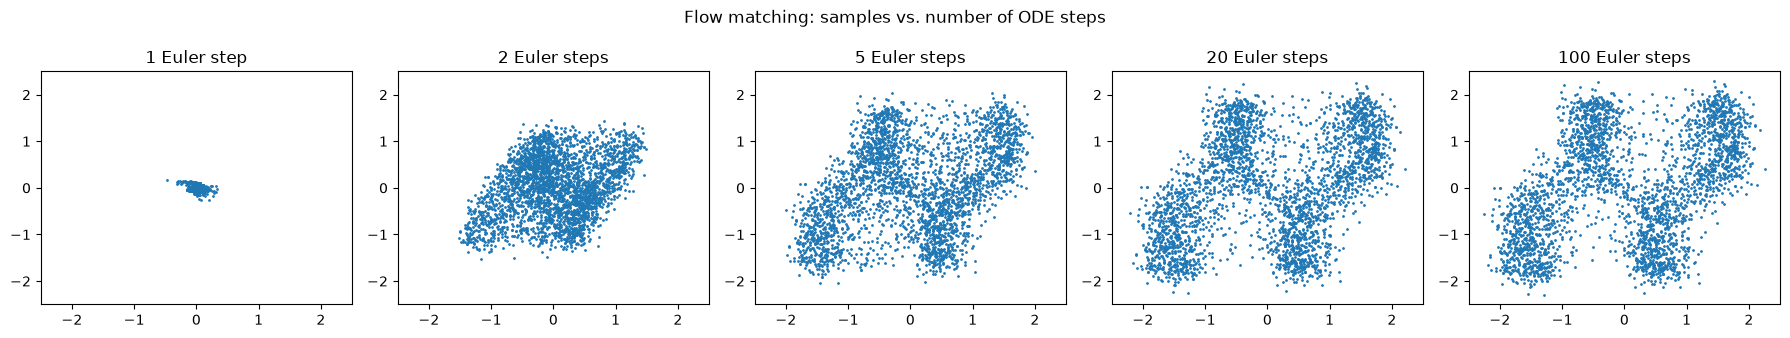

In [3]:
z = torch.randn(3000, 2, device=device)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, n in zip(axes, [1, 2, 5, 20, 100]):
    x = integrate(flow, z, n).cpu()
    ax.scatter(x[:, 0], x[:, 1], s=1); ax.set_title(f"{n} Euler step{'s' if n > 1 else ''}"); ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
plt.suptitle("Flow matching: samples vs. number of ODE steps"); plt.tight_layout(); plt.show()

## Reflow: straighten the trajectories
Pair each noise sample $z$ with the model's own output $\hat x_1 = \text{ODE}(z)$ and train again on these pairs. The learned paths become nearly straight lines, so a **single Euler step** works much better.

step     0 loss 0.1519


step  1000 loss 0.0008


step  2000 loss 0.0005


step  3000 loss 0.0004


step  4000 loss 0.0002


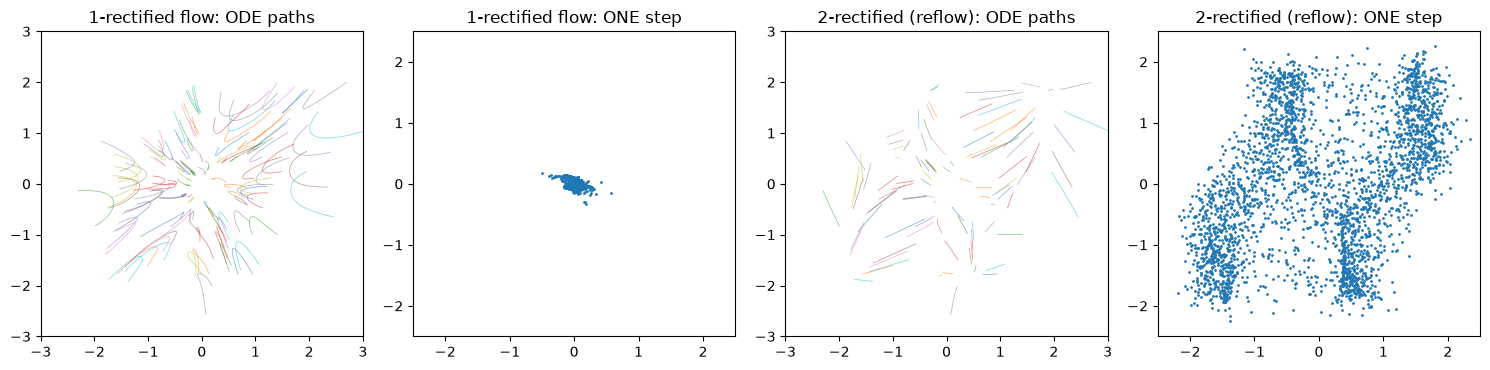

straightness (lower = straighter): flow 1.0215 | reflow 0.0003


In [4]:
with torch.no_grad():
    Z = torch.randn(50000, 2, device=device); X1 = integrate(flow, Z, 100)
def reflow_pairs(n):
    idx = torch.randint(0, len(Z), (n,), device=device); return Z[idx], X1[idx]
seed_everything(1)
flow2 = train_fm(VelocityNet().to(device), reflow_pairs)

z = torch.randn(300, 2, device=device)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for col, (m, name) in enumerate([(flow, "1-rectified flow"), (flow2, "2-rectified (reflow)")]):
    _, path = integrate(m, z, 50, keep_path=True)
    for k in range(0, 300, 3): axes[2 * col].plot(path[:, k, 0], path[:, k, 1], lw=0.5, alpha=0.6)
    axes[2 * col].set_title(f"{name}: ODE paths"); axes[2 * col].set_xlim(-3, 3); axes[2 * col].set_ylim(-3, 3)
    x = integrate(m, torch.randn(3000, 2, device=device), 1).cpu()
    axes[2 * col + 1].scatter(x[:, 0], x[:, 1], s=1); axes[2 * col + 1].set_title(f"{name}: ONE step"); axes[2 * col + 1].set_xlim(-2.5, 2.5); axes[2 * col + 1].set_ylim(-2.5, 2.5)
plt.tight_layout(); plt.show()

def straightness(m, n=2000):
    """Mean squared deviation of the velocity from the straight line (0 = perfectly straight)."""
    z = torch.randn(n, 2, device=device); x1, path = integrate(m, z, 50, keep_path=True)
    disp = (x1.cpu() - z.cpu())
    v = (path[1:] - path[:-1]) * 50
    return ((v - disp) ** 2).sum(-1).mean().item()
print(f"straightness (lower = straighter): flow {straightness(flow):.4f} | reflow {straightness(flow2):.4f}")